# Was wäre, wenn …? Ein Beispiel-Szenario

**Starter-Notebook für Projekt 1 in Informatik und Nachhaltigkeit (WiSe 2026/27)**

*Welche einzelne Änderung am Fahrplan verbessert die Erreichbarkeit des Campus am meisten, für
wie viele Menschen, und lohnt sie sich fürs Klima?*

Dieses Notebook geht den ganzen Weg einmal an einem Beispiel durch: Der Schnellbus **X13**
(Waltrop – Mengede – Huckarde – Campus Nord) fährt morgens alle 30 Minuten. Was wäre, wenn er
zwischen 6 und 9 Uhr alle 15 Minuten führe?

1. den Fahrplan ändern (eine Kopie, das Original bleibt unberührt),
2. die Kosten messen (zusätzliche Fahrzeugkilometer und -stunden),
3. die Reisezeiten zum Campus vorher und nachher mit MOTIS rechnen,
4. die Wirkung messen, gewichtet mit Einwohnerzahlen,
5. eine Vorlage für die Klimabilanz.

Die Funktionen dazu stehen in [`szenarien.py`](szenarien.py). Ihre eigenen Szenarien bauen Sie
genauso; Ideen stehen am Ende.

**Vorher:** Datenpaket holen (`python daten/herunterladen.py`). MOTIS muss nicht laufen: Für
jedes Szenario startet `motis_rechnen` einen eigenen Server (Port 8090) und beendet ihn wieder.
Beim allerersten Mal lädt es MOTIS und bereitet die Daten vor (etwa zwei Minuten).

**Rechenzeit:** etwa zweieinhalb Minuten je Szenario für ganz Dortmund (1.125 Zellen, gemessen
auf einem Laptop mit 8 Kernen). Ergebnisse werden in `nahverkehr/motis/szenarien/<name>/`
gespeichert; ein zweiter Lauf mit demselben Fahrplan dauert Sekunden.

In [1]:
from datetime import timedelta

import pandas as pd

import gtfs_hilfen as h
import reisezeitkarte as rk
import szenarien as sz

g = sz.gtfs_laden()                       # alle Tabellen des Fahrplans, Werte als Text
von, bis = h.pruefe_gueltigkeit(g)
TAG = h.tag_waehlen(g, wochentag=1, ab=von + timedelta(days=14))   # ein Dienstag mitten im Fahrplan
print(f"Gerechnet wird für Dienstag, den {TAG:%d.%m.%Y}.")

Fahrplan gültig vom 07.11.2026 bis 07.12.2026.
Gerechnet wird für Dienstag, den 24.11.2026.


## 1. Welche Linien fahren zum Campus?

Alle Linien mit Abfahrten zwischen 7 und 9 Uhr an Haltestellen im Umkreis von 600 m um den
Campus Nord (Luftlinie). Fahrten zählen in beiden Richtungen.

In [2]:
halte = g["stops"].astype({"stop_lat": float, "stop_lon": float})
nah = halte[h.entfernung_m(*rk.ZIEL, halte.stop_lat, halte.stop_lon) <= 600]
fahrten = g["trips"][g["trips"].service_id.isin(h.aktive_dienste(g, TAG))]
fahrten = fahrten.merge(g["routes"][["route_id", "route_short_name"]], on="route_id")
st = g["stop_times"][g["stop_times"].stop_id.isin(nah.stop_id)]
st = st[(st.departure_time >= "07:00:00") & (st.departure_time < "09:00:00")]
st = st.merge(fahrten[["trip_id", "route_short_name"]], on="trip_id")
st["halt"] = st.stop_id.map(nah.set_index("stop_id").stop_name)
(st.groupby("route_short_name")
   .agg(**{"Fahrten 7 bis 9 Uhr": ("trip_id", "nunique"), "Halte": ("halt", lambda s: ", ".join(sorted(set(s))))})
   .sort_values("Fahrten 7 bis 9 Uhr", ascending=False)
   .rename_axis("Linie"))

,Fahrten 7 bis 9 Uhr,Halte
Linie,,
HB2,48,Dortmund Campus Nord
HB1,24,"Dortmund Technologiezentrum, Dortmund Universität"
S1,16,Dortmund Universität
462,14,"DO-Joseph-von-Fraunhofer-Str., Dortmund Emil-F..."
445,13,"Dortmund Emil-Figge-Straße, Dortmund Meitnerwe..."
447,12,"Dortmund Groß-Barop, Dortmund Universität"
465,12,"DO-Joseph-von-Fraunhofer-Str., Dortmund Techno..."
X13,8,"Dortmund Meitnerweg, Dortmund Universität"
371,5,"DO-Joseph-von-Fraunhofer-Str., Dortmund Meitne..."


Am häufigsten fahren die H-Bahn (HB1, HB2) und die S-Bahn S1 (Bahnhof Dortmund Universität);
dazu kommen mehrere Buslinien. Die X13 kommt aus dem Nordwesten: Waltrop, Mengede, Huckarde.

## 2. Das Szenario: die X13 alle 15 statt alle 30 Minuten

`takt_verdoppeln` kopiert jede Fahrt der Linie, die zwischen 6 und 9 Uhr beginnt, und
verschiebt die Kopie um den halben Takt. Mit `tag=TAG` nimmt es nur die Fahrten, die an
diesem Dienstag fahren; die Kopien fahren an denselben Tagen wie ihre Vorbilder (hier
werktags).

In [3]:
LINIE = "X13"
neu = sz.takt_verdoppeln(g, LINIE, "06:00", "09:00", tag=TAG)
DATEI = sz.gtfs_schreiben(neu, sz.ORDNER / "x13" / "gtfs.zip")
# Abfahrten am Anfangshalt zwischen 6 und 9 Uhr, je Laufweg
f = sz.fahrten_der_linie(neu, LINIE)
f = f[f.service_id.isin(h.aktive_dienste(neu, TAG)) & f.ab.between("06:00", "09:00")]
namen = g["stops"].set_index("stop_id").stop_name
f["Laufweg"] = f.von.map(namen) + " → " + f.nach.map(namen)
f.groupby("Laufweg").ab.agg(lambda s: " ".join(sorted(t[:5] for t in s))).to_frame("Abfahrten")

Linie X13: 12 zusätzliche Fahrten mit erster Abfahrt zwischen 06:00 und 09:00 Uhr
                                           Laufweg Verkehrstag (service_id)  Takt bisher (min)  zusätzliche Fahrten
Waltrop Am Mühlenteich → Dortmund Otto-Hahn-Straße                     3146               30.0                    6
Dortmund Otto-Hahn-Straße → Waltrop Am Mühlenteich                     3146               30.0                    6


,Abfahrten
Laufweg,
Dortmund Otto-Hahn-Straße → Waltrop Am Mühlenteich,06:22 06:37 06:52 07:07 07:22 07:37 07:52 08:0...
Waltrop Am Mühlenteich → Dortmund Otto-Hahn-Straße,06:18 06:33 06:48 07:03 07:18 07:33 07:48 08:0...


## 3. Was kostet das?

Fahrzeugkilometer und Fahrzeugstunden der Linie an diesem Tag, vorher und nachher. Die
Kilometer sind Luftlinie zwischen den Halten (der Fahrplan enthält keine Linienverläufe), also
zu wenig; die Stunden zählen nur die Fahrten, ohne Wende- und Pausenzeiten. Ob für den
dichteren Takt zusätzliche Busse und Fahrerinnen und Fahrer nötig sind, steht hier nicht.

In [4]:
kosten = sz.kennzahlen(g, neu, TAG, linien=[LINIE])
kosten.style.format(precision=1, thousands=".", decimal=",")

,vorher,nachher,Differenz
Fahrten,74,86,12
Fahrzeugkilometer,"1.192,3","1.393,8","201,5"
Fahrzeugstunden,"56,6","66,3","9,7"


## 4. Reisezeiten vorher und nachher

`motis_rechnen` legt für jedes Szenario einen eigenen Ordner an, importiert den Fahrplan in
MOTIS (wenige Sekunden: das Straßennetz kommt aus dem Hauptimport), startet einen Server und
rechnet für jede Zelle des 500-m-Rasters die Reisezeit mit Bus und Bahn zum Campus: Median
über die Abfahrten 7:00, 7:05, …, 8:00 Uhr, die Wartezeit zählt mit, wie in der Karte der
[Webdemo](https://ls11ae.github.io/iun-routenplanung/reisezeit.html).

Für „nachher“ übernehmen wir die Zeiten zu Fuß, mit dem Rad und mit dem Auto von „vorher“
(`strassen=vorher`): Der Fahrplan ändert sie nicht.

In [5]:
vorher = sz.motis_rechnen(sz.GTFS, "basis", datum=TAG.isoformat())
nachher = sz.motis_rechnen(DATEI, "x13", datum=TAG.isoformat(), strassen=vorher)

basis: vorhandenes Ergebnis wiederverwendet (gerechnet in 143 s)
x13: vorhandenes Ergebnis wiederverwendet (gerechnet in 152 s)


**Schneller ausprobieren:** Mit `raster_m=1000` rechnet `motis_rechnen` nur ein Viertel der
Zellen (etwa 45 Sekunden je Szenario statt zweieinhalb Minuten); mit `punkte=[(Breite, Länge), …]` nur ausgewählte Punkte, etwa
die Zellen entlang einer Linie. Für Ergebnisse auf dem Poster bitte das ganze 500-m-Raster.

## 5. Was bringt es?

`vergleichen` gewichtet jede Zelle mit ihren Einwohnern (Zensus 2022, 100-m-Raster, auf die
500-m-Zellen summiert). Zwei Kennzahlen: Wie viele Menschen erreichen den Campus in höchstens
30 Minuten? Wie lange brauchen die Menschen in Dortmund im Mittel? Gezählt wird die Reisezeit
mit Bus und Bahn, oder zu Fuß, wenn das schneller ist. Zellen ohne Verbindung zählen beim
Mittel nicht mit.

In [6]:
tabelle, werte = sz.vergleichen(vorher, nachher, grenze_min=30)
werte.to_frame("Wert").style.format(precision=1, thousands=".", decimal=",")

,Wert
"Menschen, die den Campus in höchstens 30 min erreichen: vorher",74.125
"Menschen, die den Campus in höchstens 30 min erreichen: nachher",100.919
"mittlere Reisezeit (gewichtet mit Einwohnern, min): vorher","43,5"
"mittlere Reisezeit (gewichtet mit Einwohnern, min): nachher","43,0"
Zellen mindestens 1 min schneller,229
Menschen in diesen Zellen,126.778
Zellen mindestens 1 min langsamer,0
größte Verbesserung (min),"7,0"


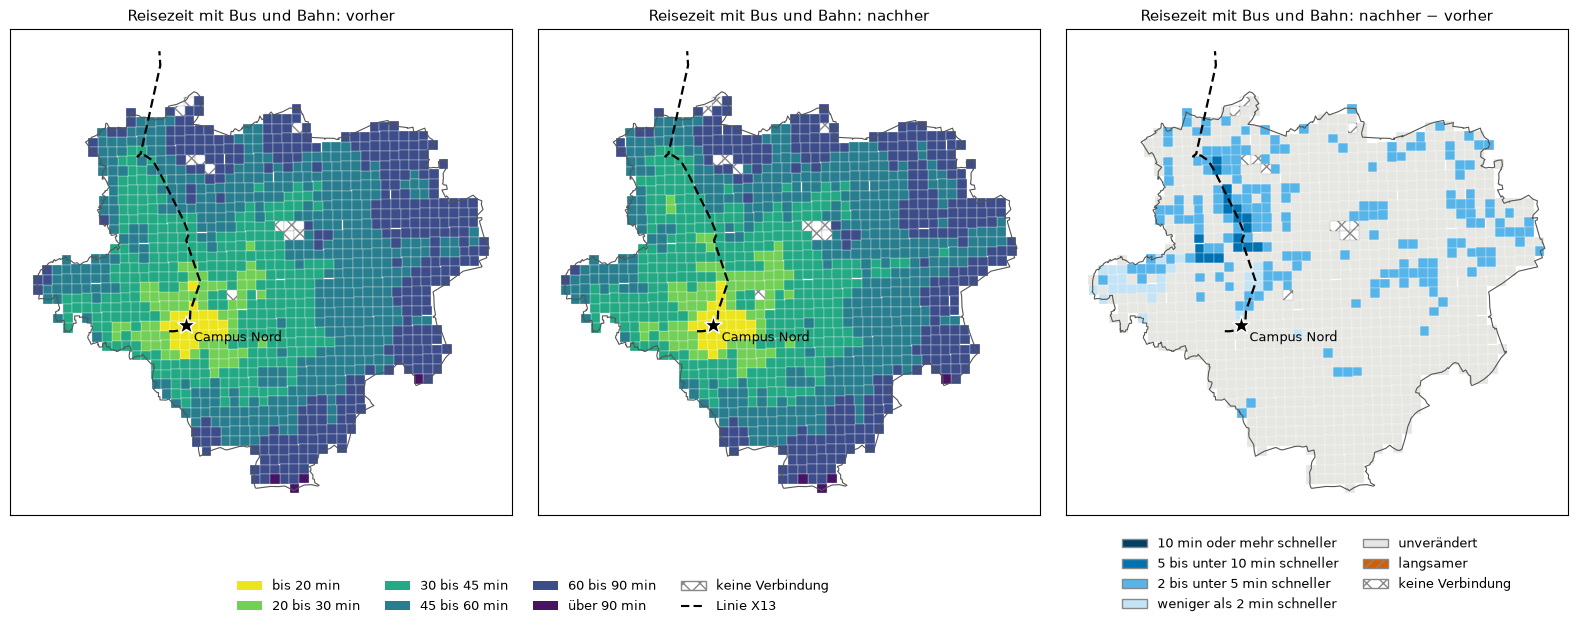

In [7]:
abb = sz.abbildung(tabelle, verlauf=sz.linienverlauf(g, LINIE), linie=LINIE)

*Die Abbildung (Stand: Fahrplan vom November 2026) zeigt drei Karten von Dortmund im 500-m-Raster. Links und Mitte: die Reisezeit
mit Bus und Bahn zum Campus Nord (Stern) vorher und nachher, in sechs Klassen von „bis 20 min“
(gelb) bis „über 90 min“ (dunkelviolett); schraffiert: keine Verbindung. Rechts: die
Differenz. Entlang der gestrichelten Linie X13 im Nordwesten werden viele Zellen 2 bis 7
Minuten schneller, einzelne Zellen auch weiter im Osten. Keine Zelle wird langsamer.*

**Lesehilfe:** Warum werden auch Zellen weit weg von der X13 schneller? Die X13 hält an
Umsteigepunkten: Huckarde Bushof (U45, U47), Wittener Straße (U43, U44) und Dorstfeld (S-Bahn).
Wer dort in die X13 umsteigt, wartet bei dichterem Takt weniger. Die zehn Zellen mit der
größten Verbesserung:

In [8]:
schneller = tabelle[tabelle.differenz < 0].sort_values(["differenz", "einwohner"], ascending=[True, False])
schneller.head(10)

,lat,lon,einwohner,vorher,nachher,differenz
399,51.53219,7.38167,978,52.0,45.0,-7.0
479,51.52320,7.38199,910,47.0,40.0,-7.0
480,51.52330,7.38920,874,42.0,35.0,-7.0
481,51.52340,7.39640,325,42.0,35.0,-7.0
437,51.52769,7.38183,1810,47.0,42.0,-5.0
442,51.52818,7.41786,1650,40.0,35.0,-5.0
441,51.52809,7.41065,1431,35.0,30.0,-5.0
115,51.56834,7.39482,1032,50.0,45.0,-5.0
328,51.54157,7.41018,888,40.0,35.0,-5.0
403,51.53258,7.41050,873,35.0,30.0,-5.0


Interaktiv, mit Stadtplan im Hintergrund (lädt Kartenkacheln von OpenStreetMap):

In [9]:
sz.differenzkarte(tabelle)

## 6. Lohnt es sich fürs Klima? Eine Vorlage

Die zusätzlichen Busse verursachen Emissionen. Dem stehen Autofahrten gegenüber, die wegfallen,
wenn Menschen umsteigen. Wer umsteigt, fährt in einem Bus mit, der ohnehin fährt; auf der
Busseite zählen deshalb nur die zusätzlichen Fahrzeugkilometer. Die Rechnung unten fragt
umgekehrt: **Wie viele Autofahrten zum Campus müssten je Werktag wegfallen, damit sich das
Szenario lohnt?**

Alle Zahlen sind Annahmen, die Sie prüfen, belegen und variieren sollten:

| Annahme | Wert | Herkunft |
|---|---|---|
| Linienbus je Fahrzeugkilometer | 1,2 kg CO2e | grobe Schätzung für einen Dieselbus: etwa 40 l Diesel je 100 km, rund 3 kg CO2e je Liter mit Vorkette. Elektrobusse liegen je nach Strom deutlich darunter. |
| Pkw je Personenkilometer | 164 g CO2e | Umweltbundesamt, Emissionsdaten Personenverkehr, Bezugsjahr 2024 (TREMOD 6.71B); ein Mittel über alle Pkw-Fahrten mit ihrer durchschnittlichen Besetzung. Wer allein fährt, verursacht je Person mehr. |
| Linienbus je Personenkilometer (zum Vergleich) | 90 g CO2e | ebenda. 1,2 kg je Buskilometer entsprechen damit einer mittleren Besetzung von gut 13 Personen. |
| Umweg | Faktor 1,3 | Weg auf der Straße im Verhältnis zur Luftlinie, für Bus und Auto |
| Länge einer Autofahrt | Luftlinie × Umweg | aus den Zellen, die schneller werden, gewichtet mit Einwohnern |

In [10]:
# Annahmen: prüfen, belegen, variieren
BUS_KG_JE_FZG_KM = 1.2      # Linienbus (Diesel), kg CO2e je Fahrzeugkilometer
PKW_G_JE_PKM = 164          # Pkw, g CO2e je Personenkilometer (Umweltbundesamt, 2024)
UMWEG = 1.3                 # Straße / Luftlinie
WERKTAGE = 250              # Tage im Jahr mit diesem Fahrplan

bus_kg = kosten.loc["Fahrzeugkilometer", "Differenz"] * UMWEG * BUS_KG_JE_FZG_KM

besser = tabelle[tabelle.differenz <= -1]
km = h.entfernung_m(besser.lat, besser.lon, *rk.ZIEL) / 1000 * UMWEG
pkw_km = (km * besser.einwohner).sum() / besser.einwohner.sum()
pkw_kg = pkw_km * PKW_G_JE_PKM / 1000
schwelle = bus_kg / pkw_kg

zahl = lambda x, stellen=0: f"{x:,.{stellen}f}".replace(",", " ").replace(".", ",").replace(" ", ".")
print(f"Zusätzliche Emissionen der Busse: {zahl(bus_kg)} kg CO2e je Werktag, {zahl(bus_kg * WERKTAGE / 1000)} t im Jahr")
print(f"Eine Autofahrt zum Campus aus den Zellen, die schneller werden: im Mittel {zahl(pkw_km, 1)} km, {zahl(pkw_kg, 1)} kg CO2e")
print(f"Damit sich das Szenario lohnt, müssten je Werktag mindestens {zahl(schwelle)} Autofahrten zum Campus wegfallen")
print(f"(in diesen Zellen wohnen {zahl(besser.einwohner.sum())} Menschen).")

Zusätzliche Emissionen der Busse: 314 kg CO2e je Werktag, 79 t im Jahr
Eine Autofahrt zum Campus aus den Zellen, die schneller werden: im Mittel 8,9 km, 1,5 kg CO2e
Damit sich das Szenario lohnt, müssten je Werktag mindestens 215 Autofahrten zum Campus wegfallen
(in diesen Zellen wohnen 126.778 Menschen).


Die Rechnung beantwortet nur, ab wann es sich lohnen *könnte*. Offene Fragen für Ihr Projekt:

- Wie viele Menschen aus diesen Zellen fahren überhaupt zum Campus (Studierende,
  Beschäftigte), und wie viele davon heute mit dem Auto?
- Steigt jemand für zwei Minuten weniger um? Was sagt die Literatur zur Wirkung von Takt
  und Reisezeit auf die Wahl des Verkehrsmittels?
- Morgens hin, nachmittags zurück: Braucht es den dichteren Takt auch für den Rückweg?
- Braucht der dichtere Takt zusätzliche Busse und Personal, und was kostet das?
- Ist eine andere Maßnahme mit denselben Fahrzeugkilometern wirksamer?

## 7. Ihre eigenen Szenarien

Jedes Szenario folgt demselben Muster: Fahrplan ändern, mit `gtfs_schreiben` unter einem
eigenen Namen speichern, mit `motis_rechnen` rechnen, mit `vergleichen` gegen `vorher`
messen, mit `kennzahlen` die Kosten bestimmen. Ideen:

1. **Neue Linie:** eine Direktverbindung aus einem Stadtteil, in dem die Karte besonders dunkel
   ist. Am einfachsten kopieren Sie Fahrten einer ähnlichen Linie und ändern Halte und Zeiten:
   eine neue Linie braucht Einträge in `routes`, `trips` und `stop_times`. Die Fahrzeiten
   zwischen den Halten schätzen Sie selbst, etwa aus vergleichbaren Linien.
2. **Abgestimmte Anschlüsse:** Wo verpasst man den Anschluss knapp? Verschieben Sie Fahrten
   einer Linie um wenige Minuten (wie in `takt_verdoppeln`: alle Zeiten einer Fahrt plus
   Versatz).
3. **Das Rad als Zubringer:** zur S-Bahn oder zur H-Bahn statt zu Fuß zur Haltestelle. Das ist
   keine Änderung am Fahrplan, sondern an der Anfrage: MOTIS kennt den Parameter
   `preTransitModes=BIKE`. Dafür erweitern Sie `reisezeitkarte.oepnv_ueber_abfahrten`.
4. **Die H-Bahn herausnehmen:** Wie wichtig ist sie für den Campus? Ihre Linien heißen im
   Fahrplan HB1, HB2, HB3, HB5 und HB7:
   `ohne = sz.linien_entfernen(g, ["HB1", "HB2", "HB3", "HB5", "HB7"])`.
5. **Der Fahrplanwechsel am 13.12. als echtes Szenario:** Das Datenpaket mit dem Fahrplan
   vorher bleibt abrufbar, auch wenn es ein neues gibt:
   `python daten/herunterladen.py --release daten-2026-11 --ziel daten/vor-fahrplanwechsel`.
   Dann `sz.motis_rechnen(Path("../daten/vor-fahrplanwechsel/dortmund-gtfs.zip"), "vor-wechsel",
   datum=…)` mit einem Tag aus dem alten Fahrplan und den neuen Fahrplan mit einem Tag aus
   dem neuen. (`herunterladen.py --liste` zeigt alle Pakete und ihre Gültigkeit.)

**Bewusst nicht vorgegeben**, das sind mögliche Teile Ihres Projekts:

- ein **Connection Scan rückwärts** (vom Campus aus) oder als **Profil** (alle Abfahrtszeiten
  in einem Durchlauf). Damit ließe sich ein Szenario für alle Zellen auf einmal rechnen,
  ohne MOTIS; einen einfachen Connection Scan vorwärts finden Sie in `csa.py`.
- eine **Optimierung über viele Maßnahmen:** Welche Kombination bringt am meisten je
  zusätzlichem Fahrzeugkilometer?
- die **Auswertung des Fahrplanwechsels**: Was hat sich geändert, für wen?

Bitte nennen Sie auf Ihrem Poster die Quellen: Fahrplan gtfs.de / DELFI e.V. (CC BY 4.0),
Karte © OpenStreetMap-Mitwirkende (ODbL), Einwohner: Zensus 2022, © Statistische Ämter des
Bundes und der Länder, 2024 (dl-de/by-2-0), Emissionsfaktoren: Umweltbundesamt, berechnet mit
MOTIS.